# 1. Dados

Como o dataset de cédulas vira as imagens usadas no treino. A lógica está em `src/data/`; este
notebook só mostra e explica os resultados. Por padrão, ele não altera nenhum arquivo.

In [1]:
import csv
import os
import sys
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

# Permite importar src/ com o notebook aberto a partir de notebooks/ ou da raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from IPython.display import Image, Markdown, display
from collections import Counter

from src.data.dataset import CLASSES, FIGURES_DIR, PROCESSED_DIR, REPORTS_DIR, print_table

# True recria data/processed/ e data/phone_test/ e baixa imagens do COCO.
GERAR_DADOS = False

## Origem

- **Cédulas:** BRL Dataset (Roboflow, CC BY 4.0), em COCO JSON.
- **`fundo`:** fotos só com moedas, pedaços sem caixa do próprio dataset e imagens do COCO 2017 com
  licença CC BY ou CC BY-SA.
- **Fotos do celular:** rotuladas à mão em `config/phone_photo_labels.csv`. Elas não são
  publicadas, então esta etapa não se reproduz por completo sem elas.

## Gerar os dados

A ordem importa: `prepare_crops` recria as pastas das cédulas, então as fotos do celular e as
composições precisam vir depois dele.

In [2]:
if GERAR_DADOS:
    from src.data import build_background, build_composites, find_near_duplicates, make_samples
    from src.data import prepare_crops, prepare_own_photos

    for step in (prepare_crops, build_background, find_near_duplicates, make_samples, prepare_own_photos, build_composites):
        step.main()
else:
    print("GERAR_DADOS = False: usando os dados que já estão em data/")

GERAR_DADOS = False: usando os dados que já estão em data/


## Orientação das fotos

Os JPEGs exportados não têm tag EXIF, mas as caixas se referem à foto já orientada. Sem corrigir
isso, os recortes saem da região errada. A rotação de cada arquivo fica em `config/orientation.csv`,
e só fotos de celular precisam girar.

In [3]:
with open("config/orientation.csv", encoding="utf-8") as file:
    rotations = Counter(int(row["rotation_degrees"]) for row in csv.DictReader(file))
print_table([[f"{angle}°", count] for angle, count in sorted(rotations.items())], ["rotação", "imagens"])

rotação  imagens
-------  -------
     0°      345
    90°      342
   180°       64
   270°       13


## Recortes das cédulas

Cada caixa vira um recorte com 10% de margem. Recortes com menor lado abaixo de 32 px e duplicatas
entre splits são descartados.

In [4]:
with (REPORTS_DIR / "crop_counts.csv").open(encoding="utf-8") as file:
    rows = list(csv.reader(file))
print_table(rows[1:], rows[0])

class  train  valid  test  total
-----  -----  -----  ----  -----
    2     63      8     5     76
    5     68      8     7     83
   10     61      9     8     78
   20     56      7    10     73
   50     61      5     8     74
  100     58     10     8     76
  200     60      4    12     76
TOTAL    427     51    58    536


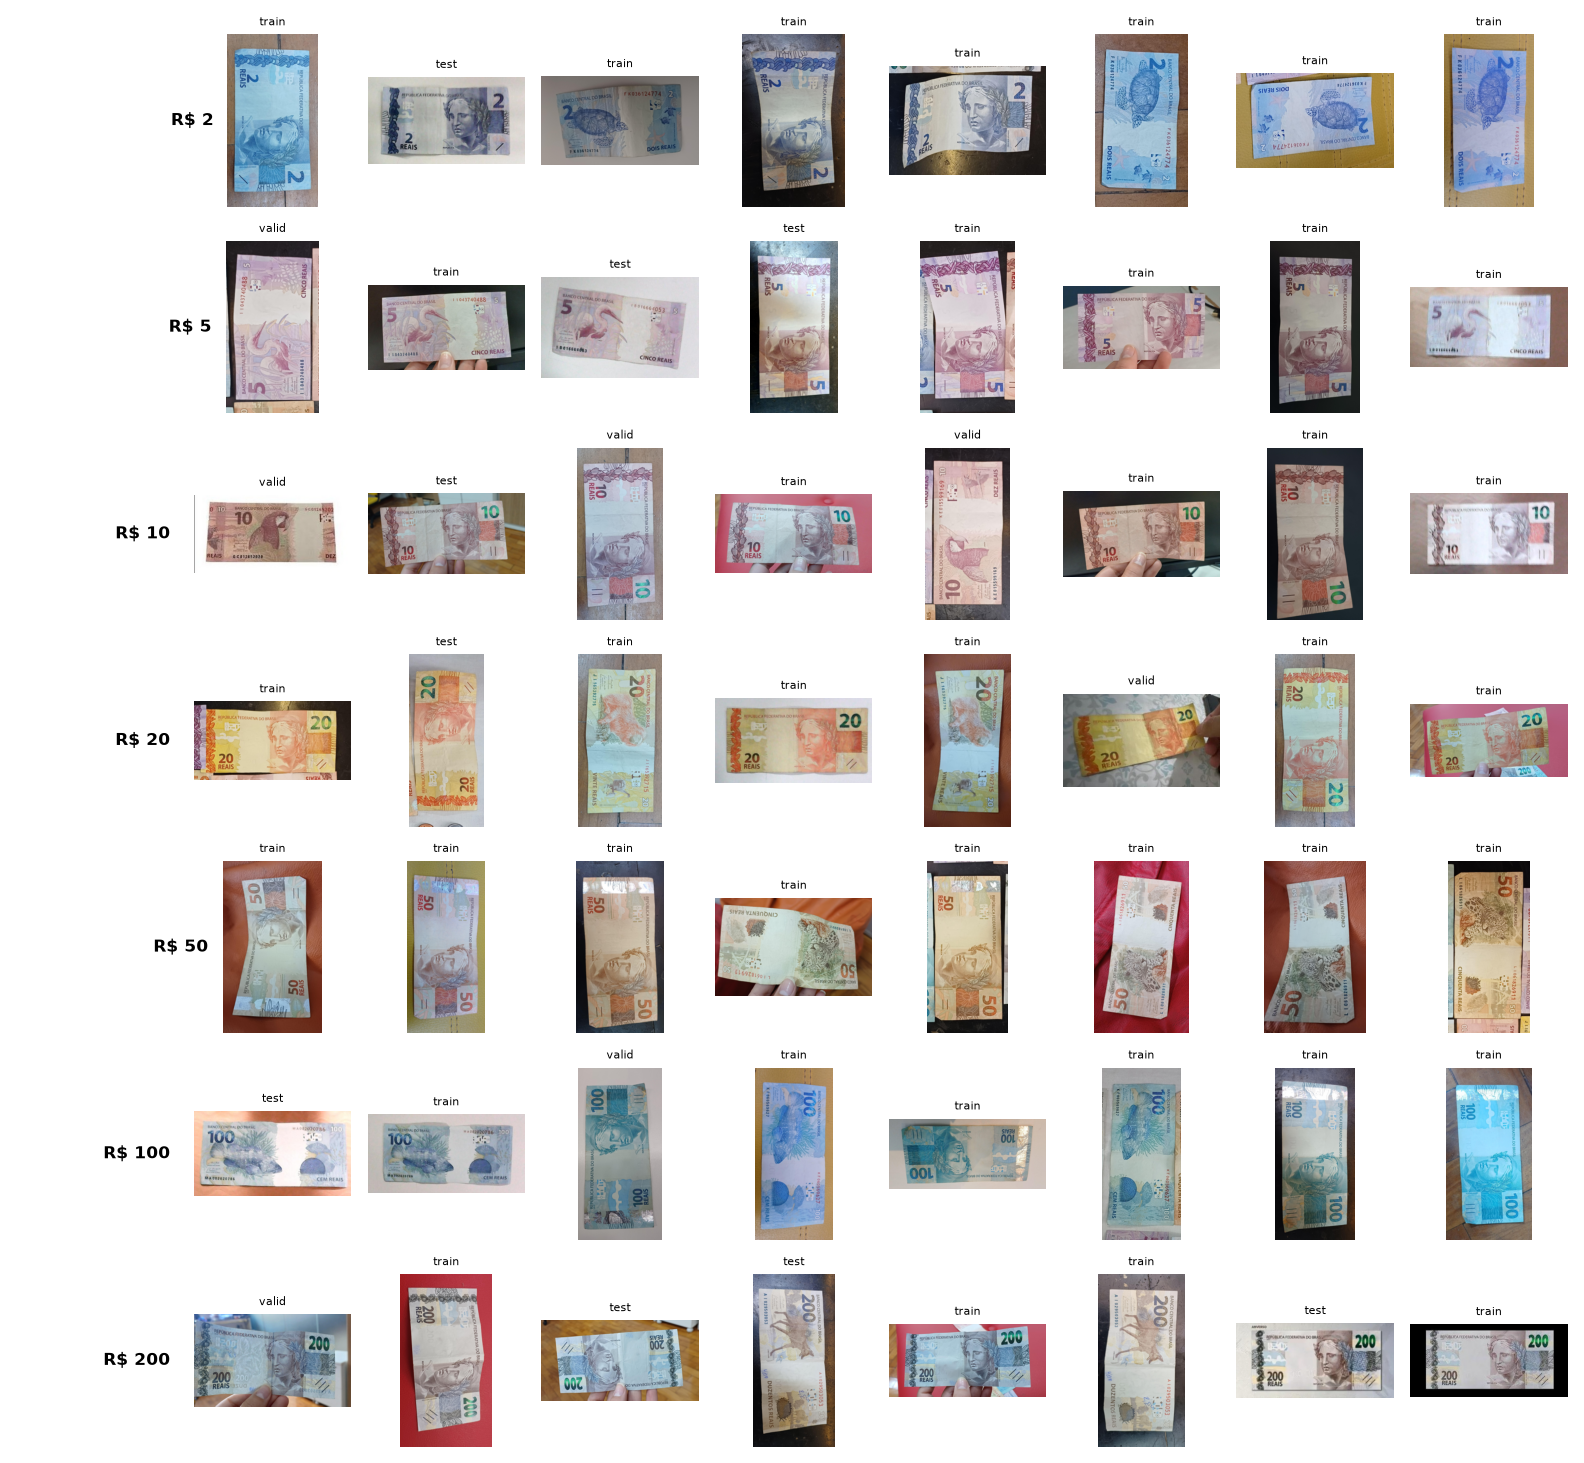

In [5]:
display(Image(FIGURES_DIR / "samples.png", width=800))

## Quase duplicatas

Fotos quase iguais em splits diferentes inflariam as métricas. Os candidatos foram conferidos a
olho, e a quase duplicata confirmada saiu do treino. Os splits ainda compartilham sessões de foto,
então valid e test tendem a ser otimistas.

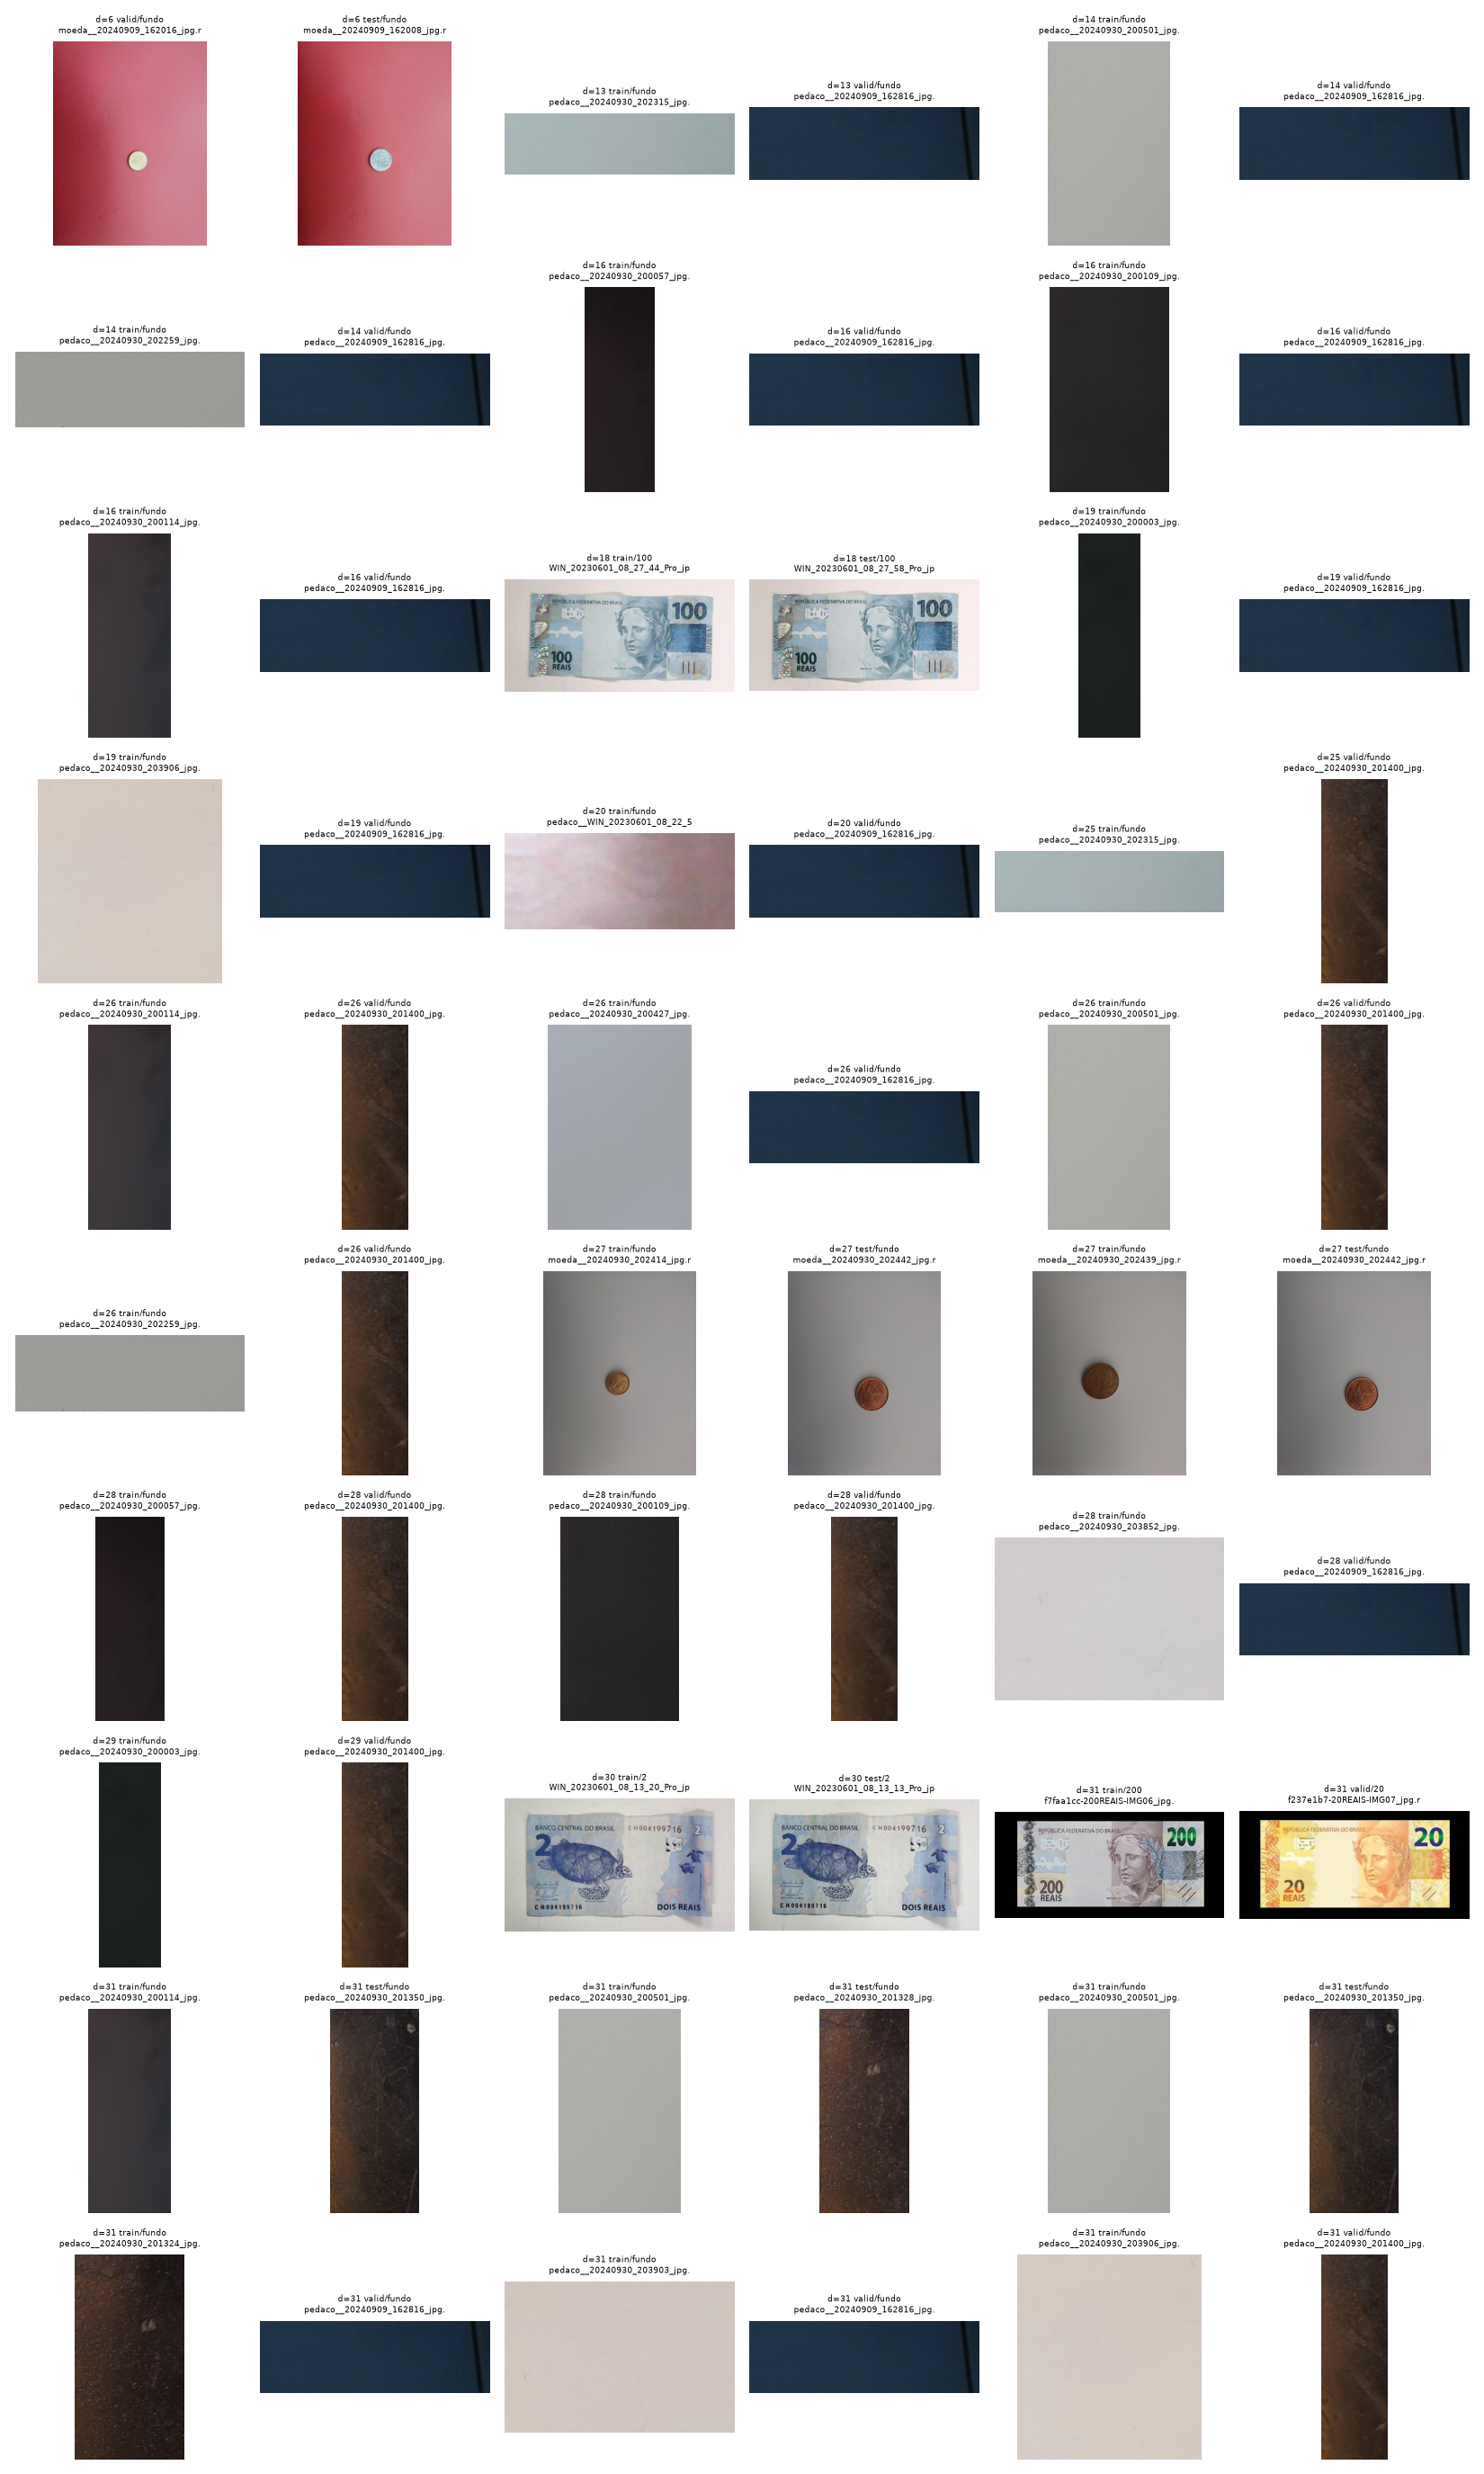

In [6]:
display(Image(FIGURES_DIR / "near_duplicates.png", width=800))

## Conjunto final de treino e validação

O treino também recebe 33 fotos do celular e 60 composições por classe: cédulas coladas sobre cenas,
e pedaços sem cédula colados no `fundo`. Sem isso, o modelo aprende a separar as classes pelo
enquadramento. O split `test` fica de fora até o modelo ser congelado.

In [7]:
rows = []
for label in [*CLASSES, "fundo"]:
    train = list((PROCESSED_DIR / "train" / label).glob("*.jpg"))
    composites = sum(path.name.startswith("composite__") for path in train)
    photos = sum(path.name.startswith("phone__") for path in train)
    valid = len(list((PROCESSED_DIR / "valid" / label).glob("*.jpg")))
    rows.append([label, len(train), composites, photos, valid])
print_table(rows, ["classe", "treino", "composições", "fotos celular", "validação"])
print(f"\nTreino: {sum(row[1] for row in rows)}  Validação: {sum(row[4] for row in rows)}")

classe  treino  composições  fotos celular  validação
------  ------  -----------  -------------  ---------
     2     225           60              2          8
     5     239           60             11          8
    10     225           60              4          9
    20     223           60              7          7
    50     221           60              0          5
   100     125           60              7         10
   200     131           60             11          4
 fundo     182           60              2         15

Treino: 1571  Validação: 66
